# 01 Explore the Safety Gate alerts

Issue #17. What is in `safetygate_alerts:1` before we build the components: which categories, risk types and origins exist, what is missing, and what `validate_alerts` (#19) has to clean.

**Data:** the local copy of the pull registered as data asset `safetygate_alerts` version 1 (tag `pull_date` = 2026-11-26): `data/raw/safetygate/2026-11-26/alerts.jsonl`, made by `ingest/safetygate.py` (#13). If it is missing, run `python ingest/safetygate.py --since 2024-01-01` from `searchashouses/`.

**Run:** from `searchashouses/`: `jupyter nbconvert --to notebook --execute notebooks/01_explore_alerts.ipynb` (packages: `notebooks/requirements.txt`).

*Contains product safety alert data from Safety Gate, the EU rapid alert system for dangerous non-food products (European Commission), © European Union, 1995-2026, CC0 1.0.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PULL = "2026-11-26"  # the pull behind safetygate_alerts:1
path = Path("../data/raw/safetygate") / PULL / "alerts.jsonl"

# dtype=False keeps every value as read: barcodes stay text, so leading zeros are not lost.
alerts = pd.read_json(path, lines=True, dtype=False)
print(f"pandas {pd.__version__}: {len(alerts):,} alerts, {alerts.shape[1]} fields")
alerts[["alert_id", "publication_date", "category", "product", "brand", "risk_types"]].head(3)

pandas 3.1.1: 12,135 alerts, 22 fields


,alert_id,publication_date,category,product,brand,risk_types
0,SR/03255/26,2026-11-18,"Clothing, textiles and fashion items",Children's rain jacket,Mountain Warehouse,"[Chemical, Environment]"
1,SR/03264/26,2026-11-13,Jewellery,Ring,Nihao Jewelry,[Chemical]
2,SR/03266/26,2026-11-13,Jewellery,Ring,NaN,[Chemical]


## 1. Overview: time range and volume

In [2]:
dates = pd.to_datetime(alerts["publication_date"])
print("first alert:", dates.min().date(), "| last alert:", dates.max().date())
print("alerts per weekly report (median):", int(alerts["report"].value_counts().median()))
dates.dt.year.value_counts().sort_index().rename("alerts per year")

first alert: 2023-12-20 | last alert: 2026-11-26
alerts per weekly report (median): 79


publication_date
2023      14
2024    4071
2025    4614
2026    3436
Name: alerts per year, dtype: int64

The first 2024 weekly report also contains a few alerts from late December 2023: `--since` filters on the report date, not on the alert date.

## 2. Completeness: which fields are empty?

In [3]:
fields = ["brand", "name", "model", "batch", "barcode", "description", "danger",
          "country_of_origin", "notifying_country", "risk_level", "online_trader", "recall_url"]
missing = alerts[fields].isna().mean()
missing["pictures (none)"] = (alerts["pictures"].str.len() == 0).mean()
missing["risk_types (none)"] = (alerts["risk_types"].str.len() == 0).mean()
(missing * 100).round(1).sort_values(ascending=False).rename("% empty").to_frame()

,% empty
online_trader,93.8
recall_url,88.7
batch,67.0
barcode,38.4
model,34.1
brand,22.1
name,10.9
description,0.0
danger,0.0
country_of_origin,0.0


Description, country of origin and risk level are always filled. The exact identifiers are often missing (barcode, model, brand), so a barcode/brand match (#26) can only work for part of the alerts; the text matcher has to do the rest.

## 3. Categories

83 categories; 54 of them are 'Other - ...' with 119 alerts in total


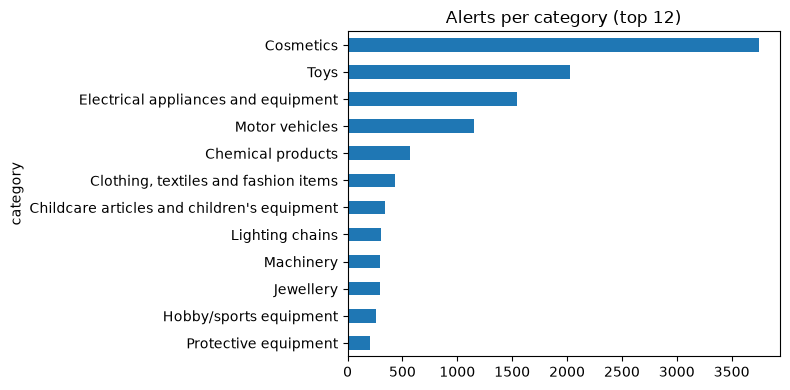

In [4]:
categories = alerts["category"].value_counts()
other = categories[categories.index.str.startswith("Other - ")]
print(f"{len(categories)} categories; {len(other)} of them are 'Other - ...' "
      f"with {other.sum()} alerts in total")
categories.head(12).sort_values().plot.barh(figsize=(8, 4), title="Alerts per category (top 12)")
plt.tight_layout()
plt.show()

## 4. Risk types: the labels for the hazard classifier

risk types per alert: {1: 10797, 2: 1152, 3: 152, 4: 33, 5: 1}
27 different labels; fewer than 50 alerts: {'Asphyxiation': 38, 'Electromagnetic disturbance': 6, 'Security': 5, 'Explosion': 5, 'Smoke inhalation': 3, 'Poisoning from inhalation': 3, 'chemical': 2, 'Abrasion': 1, 'Health risk': 1, 'Explosion and Poisoning from Inhalation': 1, 'Explosion and poisoning from inhalation': 1}


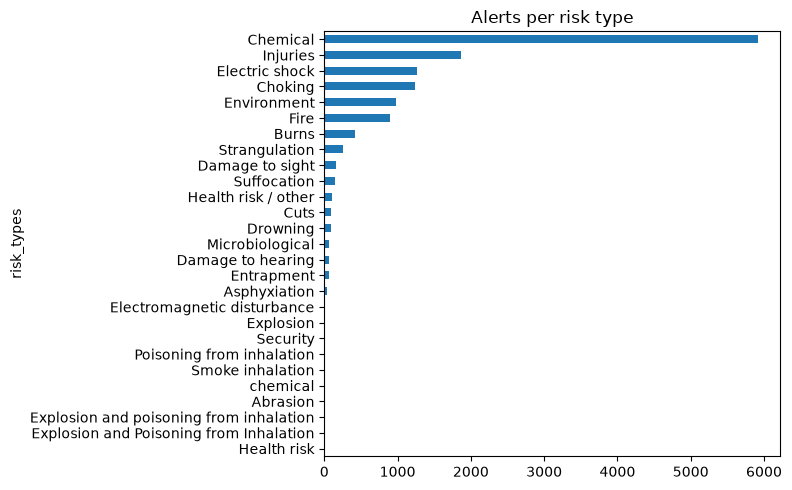

In [5]:
risk = alerts.explode("risk_types")["risk_types"].value_counts()
labels_per_alert = alerts["risk_types"].str.len().value_counts().sort_index()
print("risk types per alert:", labels_per_alert.to_dict())
print(f"{len(risk)} different labels; fewer than 50 alerts:", risk[risk < 50].to_dict())
risk.sort_values().plot.barh(figsize=(8, 5), title="Alerts per risk type")
plt.tight_layout()
plt.show()

Most alerts have one label, some have up to five, so this is a multi-label problem. The classes are very unbalanced (Chemical is by far the largest, largely from Cosmetics). The hazard classifier (#24, #25) needs class weights, macro-F1 and one threshold per risk type.

Splitting on commas is correct: no label contains a comma (`Health risk / other` uses a slash). But some rare labels are only spelling variants (`chemical` / `Chemical`, `Health risk` / `Health risk / other`, two spellings of `Explosion and poisoning from inhalation`), and a few labels have only a handful of alerts. A classifier cannot learn a label from 1-6 examples.

## 5. Risk level and "Other types of alerts"

In [6]:
print(alerts["risk_level"].value_counts().to_dict())
others = alerts[alerts["risk_level"] == "Other types of alerts"]
print("risk types in 'Other types of alerts':",
      others.explode("risk_types")["risk_types"].value_counts().head(4).to_dict())
others[["category", "product", "danger"]].head(3)

{'Serious risk': 11534, 'Other risk levels': 451, 'Other types of alerts': 150}
risk types in 'Other types of alerts': {'Environment': 70, 'Chemical': 55, 'Injuries': 10, 'Burns': 9}


,category,product,danger
6850,Electrical appliances and equipment,Karaoke microphone,The solders in the product have an excessive c...
7584,Decorative articles,Christmas decoration,The product presents a risk of cuts and injuri...
7585,Decorative articles,Christmas decoration,The sprinkles of the decoration can easily det...


"Other types of alerts" are still real product alerts (for example cadmium in solder), mostly environmental or chemical, not serious risks to the user.

## 6. Motor vehicles

In [7]:
vehicles = alerts[alerts["category"] == "Motor vehicles"]
print(f"{len(vehicles):,} alerts ({len(vehicles) / len(alerts):.0%}); "
      f"with a barcode: {vehicles['barcode'].notna().sum()}")
vehicles["product"].value_counts().head(5)

1,154 alerts (10%); with a barcode: 0


product
Passenger car                               636
Motorcycle                                   86
Passenger van / Light commercial vehicle     83
Lorry                                        64
Light commercial vehicle                     36
Name: count, dtype: int64

Motor vehicle alerts are recalls of cars, motorcycles and lorries, identified by type approval or VIN ranges, never by barcode. A marketplace listing will almost never be a car, so these alerts mostly add noise for the matcher. **Decision for #19:** keep or drop them.

## 7. Countries

In [8]:
origin = alerts["country_of_origin"].value_counts()
print(f"{origin.size} origin values; 'Unknown': {origin.get('Unknown', 0):,} alerts")
pd.DataFrame({
    "origin (top 8)": origin.head(8).index,
    "alerts": origin.head(8).values,
    "notifying country (top 8)": alerts["notifying_country"].value_counts().head(8).index,
})

89 origin values; 'Unknown': 1,173 alerts


,origin (top 8),alerts,notifying country (top 8)
0,People's Republic of China,5673,Italy
1,Italy,1419,Germany
2,Unknown,1173,France
3,Germany,671,Sweden
4,France,652,Hungary
5,Spain,317,Czechia
6,Poland,299,United Kingdom in respect of Northern Ireland
7,United Kingdom,266,Poland


One origin country has almost half of all alerts. The model must not learn "made in X = dangerous": `build_pairs` (#20) strips origin phrases from the text, and evaluate (#72) reports recall and flag rate per origin country. The notifying country is the authority that reported the alert, not where the product was sold.

## 8. Barcodes

In [9]:
barcodes = alerts["barcode"].dropna()
digits = barcodes.str.replace(r"\D", "", regex=True)
print(f"{len(barcodes):,} alerts with a barcode value; "
      f"{(barcodes != digits).sum()} contain other characters than digits")
print("number of digits:", digits.str.len().value_counts().head(6).to_dict())
print("examples:", barcodes[barcodes.str.contains(r"\D")].str[:60].head(4).tolist())

7,474 alerts with a barcode value; 237 contain other characters than digits
number of digits: {13: 6272, 12: 395, 26: 147, 8: 74, 10: 63, 11: 53}
examples: ['6970890388165  69708903881726970890388196 697089038820269708', 'Unknown', 'Unknown', '805411783779280541178378088054117837815805517693662480584803']


Most barcodes are EAN-13 (13 digits), some UPC-A (12) and EAN-8 (8). Problems to clean in #19: the word `Unknown` instead of an empty value, and **several barcodes glued together** without a separator (26, 39, ... digits = 2, 3, ... EAN-13 codes, sometimes with spaces).

## 9. Duplicates

In [10]:
same_product = alerts.dropna(subset=["brand", "model"]).duplicated(
    ["product", "brand", "model"], keep=False)
repeated_barcodes = digits[digits.str.len() == 13].value_counts()
print("alert IDs that appear twice:", alerts["alert_id"].duplicated().sum())
print("alerts that share product + brand + model with another alert:", same_product.sum())
print("EAN-13 codes in more than one alert:", (repeated_barcodes > 1).sum())

alert IDs that appear twice: 0
alerts that share product + brand + model with another alert: 181
EAN-13 codes in more than one alert: 247


Alert IDs are unique, but the same product can come back in a later alert (a new measure or another country). `build_pairs` (#20) therefore splits train and test by alert and by time, so the test set never contains an alert whose twin is in train.

## 10. Text lengths

In [11]:
lengths = pd.DataFrame({c: alerts[c].fillna("").str.len()
                        for c in ["product", "name", "description", "danger"]})
lengths.describe(percentiles=[0.5, 0.9]).loc[["50%", "90%", "max"]].astype(int)

,product,name,description,danger
50%,13,16,50,329
90%,21,41,152,482
max,49,105,400,1211


The descriptions are short (median about 50 characters), so the matcher should combine several fields: product + name + brand + model + description. `name` is often in the original language of the product (French, German, Italian, ...), which suits a multilingual encoder.

## 11. What validate_alerts (#19) must clean

1. Turn the placeholder `Unknown` (origin, barcode, ...) into an empty value.
2. Barcodes: keep digits only, split glued EAN codes into separate codes, drop impossible lengths.
3. Categories: trim double spaces; group the many one-off `Other - ...` categories into `Other`.
4. Risk types: keep the list form (multi-label); merge spelling variants (`chemical` into `Chemical`, `Health risk` into `Health risk / other`, the two `Explosion and poisoning from inhalation` spellings); group labels with fewer than 50 alerts into `Other risk` for the classifier.
5. Decide on Motor vehicles (drop or keep) and on `Other types of alerts` (keep, they are real product alerts).
6. Keep `alert_id` unique; duplicates of the same product are handled by the split in #20.

## 12. Key numbers (for the worklog)

In [12]:
summary = {
    "alerts": len(alerts),
    "date range": f"{dates.min().date()} to {dates.max().date()}",
    "categories": len(categories),
    "risk types": len(risk),
    "risk types with < 50 alerts": int((risk < 50).sum()),
    "multi-label alerts": int((alerts["risk_types"].str.len() > 1).sum()),
    "most common risk type": f"{risk.index[0]} ({risk.iloc[0]:,})",
    "rarest risk type": f"{risk.index[-1]} ({risk.iloc[-1]:,})",
    "barcode empty": f"{alerts['barcode'].isna().mean():.0%}",
    "brand empty": f"{alerts['brand'].isna().mean():.0%}",
    "model empty": f"{alerts['model'].isna().mean():.0%}",
    "origin 'Unknown'": int(origin.get("Unknown", 0)),
    "top origin": f"{origin.index[0]} ({origin.iloc[0] / len(alerts):.0%})",
    "motor vehicles": len(vehicles),
    "other types of alerts": len(others),
    "barcodes with non-digits": int((barcodes != digits).sum()),
}
pd.Series(summary, name="value").to_frame()

,value
alerts,12135
date range,2023-12-20 to 2026-11-26
categories,83
risk types,27
risk types with < 50 alerts,11
multi-label alerts,1338
most common risk type,"Chemical (5,922)"
rarest risk type,Explosion and poisoning from inhalation (1)
barcode empty,38%
brand empty,22%
